# Step 4 (supporting): Should Stories invest in personalised marketing based on customer history?

**Decision.** Personalised or targeted marketing assumes that a customer's past purchases help select valuable customers and predict what they will buy. We test whether that holds for the `Customer ID` field in this export.

**Related claim.** The export appears to show that 1,952 of 3,494 identified customers (56%) shop at all three branches. A manager could use that to argue that branches "share" (cannibalise) customers, or to build a loyalty or targeted-offer programme from purchase histories. Both uses assume that one `Customer ID` is one person with stable habits.

**What we test.** If an ID is a real person, their purchases should show *some* habit: a usual branch, a usual time of day, a usual order type or a favourite category. We compare the observed data with a **null in which the same purchases are re-labelled at random** (attributes shuffled across purchases, customer purchase counts kept). We also check whether a customer's history predicts their next purchase better than a no-history baseline on held-out data, whether selecting customers by Q1 spending picks more valuable Q2 customers than random selection, and we run a **positive control** to confirm the tests would detect habits if they existed.

Every number below is labelled **Fact** (measured), **Estimate** (depends on a model or simulation) or **Assumption**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(ROOT / "data" / "raw" / "stories_transactions.csv")
raw["Date"] = pd.to_datetime(raw["Date"])
raw["ts"] = pd.to_datetime(raw["Date"].dt.strftime("%Y-%m-%d") + " " + raw["Time"])
print(f"{len(raw):,} lines, {raw['Transaction ID'].nunique():,} purchases, {raw['Date'].min().date()} to {raw['Date'].max().date()}")

# One row per purchase. Branch, time, customer and order type are constant within a purchase.
P = (raw.groupby("Transaction ID")
        .agg(ts=("ts", "first"), Branch=("Branch", "first"), cust=("Customer ID", "first"),
             ot=("Order Type", "first"), cat=("Category", "first"),
             rev=("Line Revenue (USD)", "sum"), items=("Quantity", "sum"))
        .reset_index())
P["hour"] = P.ts.dt.hour
P["dow"] = P.ts.dt.day_name()
assert (raw.groupby("Transaction ID")[["Branch", "Order Type", "Time"]].nunique() == 1).all().all()
C = P.dropna(subset=["cust"]).sort_values("ts").reset_index(drop=True)
n_per = C.groupby("cust").size()
print(f"Identified purchases: {len(C):,} of {len(P):,} ({len(C)/len(P):.1%}); identified customers: {len(n_per):,}")

51,177 lines, 33,887 purchases, 2026-01-01 to 2026-06-30
Identified purchases: 21,534 of 33,887 (63.5%); identified customers: 3,494


## 1. Measured facts about the field

In [2]:
nb = C.groupby("cust").Branch.nunique()
print(f"Fact: customers seen at all three branches: {(nb == 3).sum():,} of {len(nb):,} ({(nb == 3).mean():.0%})")
print(f"Fact: purchases per customer: mean {n_per.mean():.2f}, variance {n_per.var():.2f}, "
      f"variance/mean {n_per.var()/n_per.mean():.2f}, max {n_per.max()}")
print("Fact: share of purchases with no Customer ID, by branch:",
      P.groupby("Branch").cust.apply(lambda s: s.isna().mean()).round(3).to_dict())
print("Fact: share with no Customer ID, by order type:",
      P.groupby("ot").cust.apply(lambda s: s.isna().mean()).round(3).to_dict())
print("Fact: branch mix of identified purchases:", C.Branch.value_counts(normalize=True).round(3).to_dict())
print("Fact: branch mix of all purchases:       ", P.Branch.value_counts(normalize=True).round(3).to_dict())

Fact: customers seen at all three branches: 1,952 of 3,494 (56%)
Fact: purchases per customer: mean 6.16, variance 6.09, variance/mean 0.99, max 18
Fact: share of purchases with no Customer ID, by branch: {'Garden': 0.368, 'Harbour': 0.363, 'Uptown': 0.364}
Fact: share with no Customer ID, by order type: {'Dine-in': 0.36, 'Takeaway': 0.371}
Fact: branch mix of identified purchases: {'Harbour': 0.483, 'Garden': 0.328, 'Uptown': 0.189}
Fact: branch mix of all purchases:        {'Harbour': 0.482, 'Garden': 0.329, 'Uptown': 0.189}


The variance/mean ratio of purchases per customer is close to **1**. That is consistent with (but does not prove) each identified purchase being given an ID drawn at random from a fixed pool of about 3,500 (a Poisson/multinomial count). **Assumption (not measured here):** real café customer bases are usually very uneven, with a few heavy regulars and many one-off visitors, which would give a ratio well above 1. The missing-ID rate is the same at every branch and for both order types, so missingness does not explain anything below.

## 2. Habit tests against a random-relabelling null

For customers with at least 5 identified purchases we measure:

* **top-branch share**: share of a customer's purchases made at their most-used branch;
* **top order-type share**: same idea for dine-in vs takeaway;
* **top-category share**: same idea for the category of the first item in the purchase;
* **hour spread**: standard deviation of the purchase hour (lower = more regular).

The null shuffles each attribute across all identified purchases, keeping how many purchases each customer has and the overall mix. We run 300 shuffles. A real habit would push the observed value outside the null range: higher shares, lower hour spread.

In [3]:
RNG = np.random.default_rng(490)
N_PERM = 300

def top_share(cust, values, keep):
    ct = pd.crosstab(cust, values)
    return (ct.max(axis=1) / ct.sum(axis=1))[keep].mean()

def habit_stats(df):
    keep = df.groupby("cust").size() >= 5
    keep = keep[keep].index
    return {
        "all three branches": (pd.crosstab(df.cust, df.Branch).gt(0).sum(axis=1) == 3).sum(),
        "top-branch share": top_share(df.cust, df.Branch, keep),
        "top order-type share": top_share(df.cust, df.ot, keep),
        "top-category share": top_share(df.cust, df.cat, keep),
        "hour spread (sd, h)": df.groupby("cust").hour.std()[keep].mean(),
    }

def shuffled(df, rng):
    s = df.copy()
    for col in ["Branch", "ot", "cat", "hour"]:
        s[col] = rng.permutation(s[col].values)
    return s

obs = habit_stats(C)
null = pd.DataFrame([habit_stats(shuffled(C, RNG)) for _ in range(N_PERM)])
rows = []
for k, v in obs.items():
    lo, hi = null[k].quantile([0.025, 0.975])
    # one-sided: habits mean higher shares / lower hour spread / fewer all-three customers
    p = ((null[k] <= v).mean() if k in ("hour spread (sd, h)", "all three branches") else (null[k] >= v).mean())
    rows.append({"statistic": k, "observed (Fact)": round(v, 3), "null mean (Estimate)": round(null[k].mean(), 3),
                 "null 95% range": f"{lo:.3f} to {hi:.3f}", "one-sided p (habit direction)": round(p, 3)})
habit_table = pd.DataFrame(rows)
habit_table

,statistic,observed (Fact),null mean (Estimate),null 95% range,one-sided p (habit direction)
0,all three branches,1952.000,1978.650,1939.950 to 2022.525,0.097
1,top-branch share,0.571,0.567,0.563 to 0.571,0.037
2,top order-type share,0.672,0.671,0.667 to 0.675,0.357
3,top-category share,0.355,0.358,0.354 to 0.362,0.927
4,"hour spread (sd, h)",4.457,4.458,4.425 to 4.487,0.467


**Reading.** Order type, category and hour spread are indistinguishable from random labels, and the number of customers seen at all three branches is *not* higher than random labels give. **So the "1,952 customers at all three branches" figure is what random assignment produces**; it is not evidence that customers move between branches. The top-branch share is at the upper edge of the null range (one-sided p ≈ 0.04, one of five tests, so weak after multiple testing). §3 shows how small any branch habit compatible with it must be.

## 3. Positive control: would these tests catch a real habit?

A null result only means something if the test could have detected an effect. We plant a modest habit in a copy of the data: each customer gets a "home" branch drawn from the overall branch mix, and each of their purchases is moved to the home branch with probability 0.3 (otherwise left as recorded). Then we rerun the top-branch test.

In [4]:
def plant_home_branch(df, rng, strength=0.3):
    s = df.copy()
    branches = s.Branch.value_counts(normalize=True)
    home = pd.Series(rng.choice(branches.index, size=s.cust.nunique(), p=branches.values), index=s.cust.unique())
    move = rng.random(len(s)) < strength
    s.loc[move, "Branch"] = s.loc[move, "cust"].map(home).values
    return s

planted = plant_home_branch(C, RNG)
pl = habit_stats(planted)
null_pl = [habit_stats(shuffled(planted, RNG))["top-branch share"] for _ in range(100)]
print(f"Planted habit (strength 0.3): top-branch share {pl['top-branch share']:.3f} vs its own null "
      f"{np.mean(null_pl):.3f} (max of 100 shuffles {np.max(null_pl):.3f}) -> detected: {pl['top-branch share'] > np.max(null_pl)}")
print(f"Planted habit: customers at all three branches {pl['all three branches']:,} (observed data: {obs['all three branches']:,})")

# Calibration: top-branch share produced by habits of different strengths
calib = pd.Series({s: np.mean([habit_stats(plant_home_branch(C, RNG, s))["top-branch share"] for _ in range(5)])
                   for s in [0.02, 0.05, 0.1, 0.2, 0.3]}, name="top-branch share")
calib.index.name = "planted habit strength"
print(f"\nObserved top-branch share {obs['top-branch share']:.3f}; random-label null {null['top-branch share'].mean():.3f}")
print(calib.round(3).to_string())

Planted habit (strength 0.3): top-branch share 0.622 vs its own null 0.569 (max of 100 shuffles 0.573) -> detected: True
Planted habit: customers at all three branches 1,642 (observed data: 1,952)



Observed top-branch share 0.571; random-label null 0.567
planted habit strength
0.02    0.572
0.05    0.573
0.10    0.576
0.20    0.592
0.30    0.620


The test easily detects a habit where only 30% of a customer's purchases are steered to a home branch. The observed top-branch share (0.571) is far below the 0.62 produced by the planted 30% habit. So the result in §2 is **not** due to a weak test: a modest branch habit of that size would be visible. The calibration table is shown for reference only; with 5 repetitions per strength it is too coarse to set a precise upper bound, and the data cannot rule out a weak habit.

## 4. Held-out prediction: does a customer's history help predict their next purchase?

This is the practical version of the question. A loyalty or targeting system works only if past purchases predict future ones.

* **Held-out data:** for every customer with at least 5 identified purchases, the **last** purchase in time is the test set and is used only once, at the end.
* **Baseline:** predict from the overall mix of all history purchases (no customer information).
* **Model:** the customer's own history, shrunk toward the overall mix (Dirichlet smoothing with prior weight α; large α = trust the baseline, small α = trust the customer's history). α is chosen on a **separate validation purchase** (the second-to-last, predicted from the purchases before it), never on the test purchase.
* **Metrics:** log-loss (lower is better) and accuracy of the most likely class, with a bootstrap 95% range for the difference **history log-loss − baseline log-loss**. **Sign:** a negative difference means history predicts better; zero means no improvement; positive means history is worse.

The same test is run on the planted-habit copy from §3 as a check that the method can find signal.

In [5]:
ALPHAS = [0.5, 1, 2, 4, 8, 16, 32, 64, 128, 1e6]

def predict(hist, target, col, classes, alpha):
    # returns per-target-purchase probabilities (history model) and baseline probabilities
    g = hist[col].value_counts(normalize=True).reindex(classes).fillna(0).values
    ct = pd.crosstab(hist.cust, hist[col]).reindex(columns=classes, fill_value=0).reindex(target.cust).fillna(0).values
    post = (ct + alpha * g) / (ct.sum(axis=1, keepdims=True) + alpha)
    y = np.array([classes.index(v) for v in target[col]])
    return post, g, y

def heldout(df, col, n_boot=1000, rng=RNG):
    df = df.sort_values("ts")
    k = df.groupby("cust").size()
    df = df[df.cust.isin(k[k >= 5].index)]
    classes = sorted(df[col].unique())
    test = df.groupby("cust").tail(1)
    rest = df.drop(test.index)
    val = rest.groupby("cust").tail(1)
    # 1) choose alpha on the validation purchase only
    val_ll = {}
    for a in ALPHAS:
        post, g, y = predict(rest.drop(val.index), val, col, classes, a)
        val_ll[a] = -np.log(post[np.arange(len(y)), y]).mean()
    alpha = min(val_ll, key=val_ll.get)
    # 2) score once on the test purchase, history = everything before it
    post, g, y = predict(rest, test, col, classes, alpha)
    ll_m = -np.log(post[np.arange(len(y)), y])
    ll_b = -np.log(g[y])
    diff = ll_m - ll_b
    boot = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(n_boot)]
    return {"target": col, "held-out purchases": len(y), "chosen α": alpha,
            "baseline log-loss": round(ll_b.mean(), 4), "history log-loss": round(ll_m.mean(), 4),
            "difference (history - baseline)": round(diff.mean(), 4),
            "95% range of difference": f"{np.percentile(boot, 2.5):+.4f} to {np.percentile(boot, 97.5):+.4f}",
            "baseline accuracy": round((post.argmax(1) * 0 + g.argmax() == y).mean(), 3),
            "history accuracy": round((post.argmax(1) == y).mean(), 3)}

C["hour band"] = pd.cut(C.hour, [0, 11, 17, 24], labels=["morning", "afternoon", "evening"]).astype(str)
planted["hour band"] = C["hour band"]
pred = pd.DataFrame([heldout(C, c) for c in ["Branch", "ot", "cat", "hour band"]]
                    + [dict(heldout(planted, "Branch"), target="Branch (planted habit, control)")])
pred

,target,held-out purchases,chosen α,baseline log-loss,history log-loss,difference (history - baseline),95% range of difference,baseline accuracy,history accuracy
0,Branch,2557,128.0,1.0261,1.0261,0.0000,-0.0010 to +0.0010,0.496,0.496
1,ot,2557,1000000.0,0.6749,0.6749,-0.0000,-0.0000 to +0.0000,0.595,0.595
2,cat,2557,1000000.0,2.0719,2.0719,0.0000,-0.0000 to +0.0000,0.208,0.208
3,hour band,2557,1000000.0,1.0087,1.0087,0.0000,-0.0000 to +0.0000,0.520,0.520
4,"Branch (planted habit, control)",2557,8.0,1.0223,0.9909,-0.0313,-0.0425 to -0.0200,0.502,0.524


**Reading.** On the real data, validation chooses a very large α for every target: the best use of a customer's history is to almost ignore it. On the test purchase, history then adds nothing over the baseline (difference 0.000, accuracy unchanged). With a small α, history would make predictions *worse*. On the planted-habit copy, validation chooses a small α and history clearly improves log-loss on the test purchase, with a range that excludes zero. So the method finds signal when there is signal to find.

**Estimate, not fact:** this says that *in this export*, `Customer ID` carries no usable information about where, when or what a customer will buy next. It does not prove why.

## 4b. Targeting test: does selecting customers by Q1 spending pick more valuable Q2 customers?

This mirrors the marketing decision. **Eligibility:** only customers with at least one identified purchase in Q1 can be selected, because a marketer at the end of March could not target anyone else. The same eligible pool is used for both the targeted and the random selections. Rank eligible customers by Q1 (Jan–Mar) gross profit, select the top 10%, 20% or 30%, and measure the Q2 (Apr–Jun) gross profit **subsequently observed** from them. Compare with 5,000 random selections of the same size.

This is observed gross profit from selected customers. It is **not** profit caused by a marketing campaign, and not money lost or gained. No campaign is simulated.

In [6]:
gpq = raw.dropna(subset=["Customer ID"]).assign(q=lambda x: np.where(x.Date < "2026-04-01", "Q1", "Q2"))
S_all = gpq.pivot_table(index="Customer ID", columns="q", values="Line Gross Profit (USD)", aggfunc="sum", fill_value=0)
q1_ids = gpq.loc[gpq.q == "Q1", "Customer ID"].unique()
S = S_all.loc[q1_ids]  # eligibility: seen in Q1; Q2 GP is 0 for eligible customers with no Q2 purchase
rows = []
for frac in [0.10, 0.20, 0.30]:
    k = int(len(S) * frac)
    sel = S.Q2.loc[S.Q1.nlargest(k).index].sum()
    rnd = np.array([S.Q2.values[RNG.choice(len(S), k, replace=False)].sum() for _ in range(5000)])
    rows.append({"selected": f"top {frac:.0%} by Q1 GP ({k} customers)",
                 "Q2 GP of selected (Fact)": round(sel), "random selections: mean (Estimate)": round(rnd.mean()),
                 "random 95% range": f"{np.percentile(rnd, 2.5):,.0f} to {np.percentile(rnd, 97.5):,.0f}",
                 "share of random selections that did at least as well": round((rnd >= sel).mean(), 3)})
target_table = pd.DataFrame(rows)
print(f"Eligible (seen in Q1): {len(S):,} of {len(S_all):,} identified customers; their Q2 GP ${S.Q2.sum():,.0f}; "
      f"eligible with no Q2 purchase: {(S.Q2 == 0).sum()}")
target_table

Eligible (seen in Q1): 3,255 of 3,494 identified customers; their Q2 GP $60,023; eligible with no Q2 purchase: 112


,selected,Q2 GP of selected (Fact),random selections: mean (Estimate),random 95% range,share of random selections that did at least as well
0,top 10% by Q1 GP (325 customers),5674,5992,"5,626 to 6,359",0.953
1,top 20% by Q1 GP (651 customers),11410,12008,"11,497 to 12,512",0.988
2,top 30% by Q1 GP (976 customers),17487,17997,"17,448 to 18,573",0.964


**Reading.** At no cut point does selecting by Q1 spending capture more Q2 gross profit than random selection. At the top 10% and top 30%, the selected customers' Q2 gross profit is inside the random 95% range, near its lower end. At the top 20% it is slightly *below* the range (about 5% under the random mean; 99% of random selections did at least as well). We do **not** conclude that "targeting performs worse". The shortfall is small, it comes from a single Q1→Q2 split, the three cut points overlap (the top 10% is inside the top 20%), and the test was not fixed in advance. The supported conclusion is the weaker one:

> **Selecting customers by Q1 spending showed no demonstrated advantage over random selection for Q2 gross profit. Validate customer-history targeting before committing marketing budget.**

## 5. Spend persistence and very short gaps between branches

In [7]:
C["half"] = np.where(C.ts < "2026-04-01", "Q1", "Q2")
spend = C.pivot_table(index="cust", columns="half", values="rev", aggfunc="sum", fill_value=0)
obs_r = spend.corr(method="spearman").iloc[0, 1]
null_r = []
for _ in range(200):
    s = C[["cust", "half", "rev"]].copy()
    s["cust"] = RNG.permutation(s.cust.values)
    sp = s.pivot_table(index="cust", columns="half", values="rev", aggfunc="sum", fill_value=0)
    null_r.append(sp.corr(method="spearman").iloc[0, 1])
print(f"Q1 vs Q2 spend per customer, Spearman correlation: observed {obs_r:.3f} (Fact); "
      f"random-relabelling null {np.mean(null_r):.3f}, 95% range {np.percentile(null_r, 2.5):.3f} to {np.percentile(null_r, 97.5):.3f} (Estimate)")

C["prev_branch"] = C.groupby("cust").Branch.shift()
C["gap_min"] = C.groupby("cust").ts.diff().dt.total_seconds() / 60
pairs = C.dropna(subset=["prev_branch"])
for lim in [10, 30]:
    x = pairs[pairs.gap_min <= lim]
    print(f"Fact: consecutive purchases by the same ID within {lim} min: {len(x)}, of which {(x.Branch != x.prev_branch).sum()} at a different branch")
print(f"Fact: share of all consecutive same-ID purchase pairs that switch branch: {(pairs.Branch != pairs.prev_branch).mean():.1%}")

Q1 vs Q2 spend per customer, Spearman correlation: observed -0.023 (Fact); random-relabelling null -0.004, 95% range -0.029 to 0.024 (Estimate)
Fact: consecutive purchases by the same ID within 10 min: 11, of which 8 at a different branch
Fact: consecutive purchases by the same ID within 30 min: 35, of which 23 at a different branch
Fact: share of all consecutive same-ID purchase pairs that switch branch: 62.4%


* Customers who spent more in Q1 do not spend more in Q2 than random labels would imply (a real customer base usually shows strong persistence; **assumption**, from general retail experience, not measured here).
* A handful of IDs buy at two different branches within 10 minutes. We do not know the distance between branches, so this is **weak supporting evidence only**, not proof of an error.

## 6. Alternative explanations

| Explanation | What it predicts | What we see | Verdict |
|---|---|---|---|
| Customers genuinely roam between nearby branches | Even roamers keep habits: a usual time, order type or favourite category | No habit of any kind (§2), history does not predict (§4) | Does not explain the data |
| A few shared "house" or staff loyalty cards absorb many purchases | Some IDs with very large counts; variance/mean far above 1 | Max 18 purchases; variance/mean ≈ 1 (§1) | Rejected |
| IDs recycled or re-issued during the period | Habits would hold within short windows | Not tested separately; the held-out test uses each customer's most recent purchase, and no habit appears | Possible, not tested |
| ID attached to the purchase without regard to the person, by the POS, the export process, or the way this dataset was produced (Transaction IDs start with `SYN-`, which *may* indicate synthetic data; this is a hypothesis, not established) | The pattern of §1–§5 | Consistent | **Consistent with all tests, but the data cannot identify the mechanism** |
| Missing IDs bias the picture | Missingness differs by branch, order type or time | Equal by branch and order type (§1) | Rejected as main cause |

The finding is therefore stated narrowly: **in this export, we found no evidence that `Customer ID` carries stable customer habits, and customer history showed no demonstrated predictive or selection advantage. This does not prove the IDs are random or useless; it means their usefulness for customer-level decisions has not been demonstrated and should be validated first.**

## 7. Business value: assumptions and estimate

**What is measured:** the customer-level statistics we tested fall within (or at the edge of) the range produced by random relabelling; held-out history gives no demonstrated predictive lift; selecting by Q1 spending shows no demonstrated advantage for Q2 gross profit.

**What it protects against (decision value, not cash):**
1. **"Branches share their customers" / cannibalisation arguments** (e.g. in a decision about Uptown, the smallest branch): the 56% "all three branches" figure is about what random relabelling produces, so it is not evidence of customers moving between branches.
2. **Loyalty, CRM or targeted-offer spending based on these IDs:** no demonstrated advantage of history-based selection over random selection (§4, §4b).
3. **Customer-level KPIs** (repeat rate, customer lifetime value, churn): any such number from this field would mostly reflect how IDs are attached, not customer behaviour.

**Why we give no dollar figure.** The data contains no loyalty-programme costs, CRM spend or plans for one. Any dollar value would be invented. The value is the cost of a wrong customer-level decision avoided, and that depends on decisions we cannot see. This is a **weakness compared with the Garden costing finding**, which has a measured $15,923 recorded-cost gap.

In [8]:
print(f"Fact: identified purchases carry ${C.rev.sum():,.0f} of ${P.rev.sum():,.0f} H1 revenue ({C.rev.sum()/P.rev.sum():.0%}), "
      "i.e. the share of revenue any customer-level analysis would rely on.")

Fact: identified purchases carry $194,203 of $305,925 H1 revenue (63%), i.e. the share of revenue any customer-level analysis would rely on.


## 8. Practical test Stories can run

1. **Audit (1 day):** ask the POS team how `Customer ID` is attached to a purchase (loyalty card scan, phone number, cashier default) and whether the export joins it by transaction.
2. **Capture pilot (4 weeks, one branch):** require a verified identifier (phone number or app scan) on identified purchases. Re-run §2 and §4 on the pilot data.
3. **Pass criterion, fixed in advance:** top-branch share above the 97.5th percentile of the random-relabelling null *and* a held-out log-loss improvement whose 95% range excludes zero. Only then use the field for loyalty or branch-overlap decisions.

## 9. Screened alternatives (not chosen)

We screened the two other candidate patterns before choosing this one.

In [9]:
daily = P.groupby(["Branch", P.ts.dt.normalize()]).size().rename("n").reset_index()
daily["dow"] = daily.ts.dt.day_name()
wkday = daily[~daily.dow.isin(["Saturday", "Sunday"])]
ratio = wkday.groupby(["Branch", wkday.dow == "Tuesday"]).n.mean().unstack()
print("Fact: Tuesday purchases / other-weekday average, by branch:", (ratio[True] / ratio[False]).round(2).to_dict())

wk = P[~P.dow.isin(["Saturday", "Sunday"])].copy()
wk["tue"] = wk.dow == "Tuesday"
def tue_ratio(by):
    r = wk.groupby([by, "tue"]).size().unstack()
    return (r[True] / (r[False] / 4)).round(2)
print("Fact: Tuesday ratio by hour, min-max:", tue_ratio("hour").min(), "-", tue_ratio("hour").max())
print("Fact: Tuesday ratio by first-item category, min-max:", tue_ratio("cat").min(), "-", tue_ratio("cat").max())
week = P.assign(week=P.ts.dt.to_period("W")).groupby(["week", "dow"]).size().unstack()
full = week.dropna()
print(f"Fact: Tuesday is the busiest day in {(full.idxmax(axis=1) == 'Tuesday').sum()} of {len(full)} complete weeks")
print("Fact: basket (revenue per purchase) by weekday:", P.groupby("dow").rev.mean().round(2).to_dict())

hr = P.groupby("hour").size()
print("Fact: purchases by hour (all branches):", hr.to_dict())
print("Fact: revenue per purchase, 07:00 vs 21:00:", round(P[P.hour == 7].rev.mean(), 2), "vs", round(P[P.hour == 21].rev.mean(), 2))

Fact: Tuesday purchases / other-weekday average, by branch: {'Garden': 1.56, 'Harbour': 1.53, 'Uptown': 1.52}
Fact: Tuesday ratio by hour, min-max: 1.34 - 1.72
Fact: Tuesday ratio by first-item category, min-max: 1.36 - 1.68
Fact: Tuesday is the busiest day in 25 of 25 complete weeks
Fact: basket (revenue per purchase) by weekday: {'Friday': 8.94, 'Monday': 9.01, 'Saturday': 9.2, 'Sunday': 9.13, 'Thursday': 8.98, 'Tuesday': 9.03, 'Wednesday': 8.98}
Fact: purchases by hour (all branches): {7: 724, 8: 1040, 9: 1533, 10: 1480, 11: 1483, 12: 1537, 13: 1789, 14: 1779, 15: 1785, 16: 1858, 17: 1814, 18: 2084, 19: 2586, 20: 3185, 21: 4273, 22: 3255, 23: 1682}
Fact: revenue per purchase, 07:00 vs 21:00: 8.89 vs 9.06


**Tuesday (+≈55%).** Real and large, but the uplift is almost the same at every branch, every hour, every category and every complete week, with no change in basket. That is what a single multiplier on Tuesday would produce. We found no event, menu or price change that would explain it. The obvious action (staff Tuesdays more) needs labour and stock data that the export does not contain, so we cannot value it. It is also the most visible pattern in the data, so it is unlikely to be original. **Not chosen.**

**Late night (peak at 21:00, low at 07:00).** Also real, but deciding on opening hours needs labour, rent and energy costs per hour, which we do not have. Revenue per purchase is similar across hours, so the export gives no margin argument either way. **Not chosen.**

## 10. Rejected approaches and weak areas

* **Rejected:** clustering customers into segments (RFM, k-means). Segments can always be produced, but §2–§4 show that the inputs carry no stable signal, so the segments would be noise.
* **Rejected:** a gradient-boosted next-purchase model. The simple smoothed-history model already shows zero lift over the baseline; a more flexible model would only fit noise more confidently.
* **Screened, not pursued:** market-basket complements. Category pairs in multi-item purchases do show structure beyond random shuffling (e.g. Sandwiches + Cold Drinks), but this is a standard analysis, and co-purchase alone cannot show that removing a product would cost sales.
* **Weak areas:** (1) we cannot see how IDs are captured, so the mechanism is unknown; (2) the very-short-gap evidence depends on branch distances we do not have; (3) the "real customers are uneven and persistent" benchmarks are general assumptions, not measured on comparable cafés; (4) the business value is a decision-protection argument with no dollar figure.

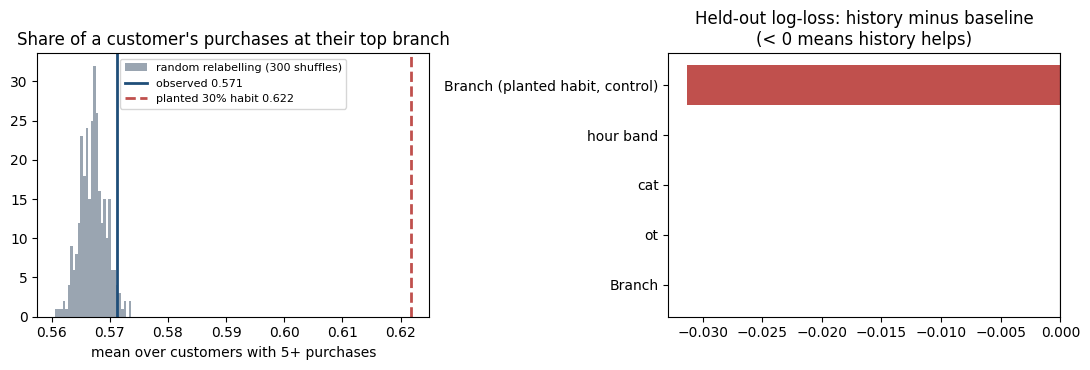

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(null["top-branch share"], bins=30, color="#9aa5b1", label="random relabelling (300 shuffles)")
ax[0].axvline(obs["top-branch share"], color="#1f4e79", lw=2, label=f"observed {obs['top-branch share']:.3f}")
ax[0].axvline(pl["top-branch share"], color="#c0504d", lw=2, ls="--", label=f"planted 30% habit {pl['top-branch share']:.3f}")
ax[0].set_title("Share of a customer's purchases at their top branch")
ax[0].set_xlabel("mean over customers with 5+ purchases"); ax[0].legend(fontsize=8)
d = pred.set_index("target")["difference (history - baseline)"]
ax[1].barh(d.index, d.values, color=["#1f4e79"] * (len(d) - 1) + ["#c0504d"])
ax[1].axvline(0, color="black", lw=0.8)
ax[1].set_title("Held-out log-loss: history minus baseline\n(< 0 means history helps)")
fig.tight_layout()
fig.savefig(FIG / "alt_customer_id.png", dpi=150)
plt.show()